# Lab: Basic Image Processing

## Goal of this lab

Getting familiar with basic image processing operations:
* Reading in images and plotting them
* Basic transforms (transpose, rotate, scale, etc.)
* Basic image operations (add, subtract, multiply, divide)
* Image thresholding (basic image segmentation)
* Contrast enhancement
* Image averaging on an image sequence

## Required reading
* Matplotlib introduction: http://www.datadependence.com/2016/04/scientific-python-matplotlib/
* scikit-image introduction: https://github.com/scikit-image/skimage-tutorials/blob/master/lectures/00_images_are_arrays.ipynb


## Required packages
* numpy
* matplotlib
* scipy
* scikit-image (skimage)
* imageio

You can execute individual code blocks by pressing SHIFT+Enter consecutively.

You can trigger auto completion with TABULATOR

## Import required packages

In [12]:

import numpy as np
from scipy import ndimage #ndimage provides a large amount of functions for image processing: https://docs.scipy.org/doc/scipy/reference/ndimage.html
from skimage import color #many tutorials: https://github.com/scikit-image/skimage-tutorials/tree/master/lectures
import matplotlib.pyplot as plt # matplotlib is the major lib for plotting
import imageio.v2 as imageio

## Exercise 1
### Read in images

1. Read in image "einstein.jpg" into a variable "im" (use the function *imageio.imread()*)
2. Print: the size of the image (with .shape)
3. What kind of datatype is the image? Check out with "type(im)"
4. What kind of values does the image store? Check out with im.dtype
5. What are maximum, minimum and mean values of the image? Check out with functions np.max, np.min and np.mean

Note: on Windows, do not use backslash ("\"), use forward slash "/" instead!

In [13]:
im = imageio.imread('../../data/test_images/einstein.jpg')
print(im.shape)
print(type(im))
print(im.dtype)
np.max(im)
np.min(im)
np.mean(im)

(256, 256)
<class 'numpy.ndarray'>
uint8


np.float64(109.00067138671875)

### Plot the image

1. Use plt.imshow() to plot the image. If colors (brightness values) look strange, explicitly provide the colormap in the call to plt.imshow(), i.e. cmap="gray". imshow does not directly show the image. run plt.show() to display it
2. Save the fig to a file: foo.jpg in the current directory with *imageio.imwrite()*.

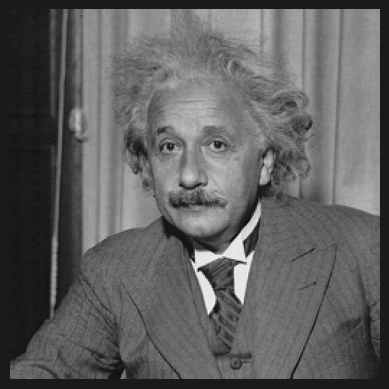

In [14]:
plt.imshow(im, cmap='gray')
plt.axis('off')
plt.show()
imageio.imwrite('foo.jpg', im)

### Read in color image and plot it:

1. Read in catDog.jpg into a variable imColor
2. Show the image (as above). Note: here you do not need to provide a color map, because per default color images are assumed by the function
3. Print the dimensions of the variable imColor (with .shape) and its type and its dtype (as above)

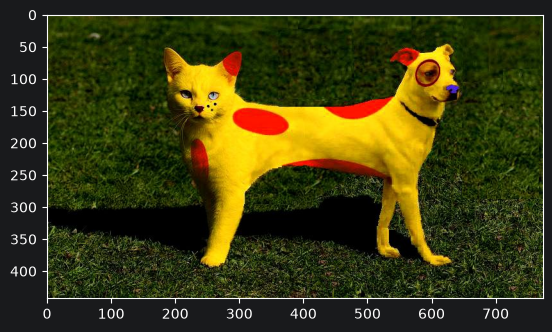

(443, 774, 3)
<class 'numpy.ndarray'>
uint8


In [15]:
imColor = imageio.imread(r'../../data/test_images/catDog.jpg')
plt.imshow(imColor)
plt.show()
print(imColor.shape)
print(type(imColor))
print(imColor.dtype)

## Exercise 2
### Manipulating pixels

Now that we can load and show pictures, we can try to manipulate them. This is easy, as the images are stored directly as matrices. Changing values in the matrices, directly changes pixels!

1. Take the "einstein" image from before (variable "im")
2. Cut out a part of the image (which part, depends on you). To cut out a part of the image use syntax: im[a:b,c:d] where a, b, c, and d are row and column indices defined by you. Note, that this does not produce a real copy. Use the function np.copy(...) to make a real copy! Plot the image, once you have cut it out. 
3. Try to add a "censor bar" to the image, i.e. a black bar in front of einstein's eyes. To do this, set a rectangular area in the image "im" to zero. You can address and specify this area with the same syntax as above: im[a:b,c:d]. Plot the modified image im. 
4. Save the image to disk with function imageio.imsave() and give it the name 'einstein_censored.png'



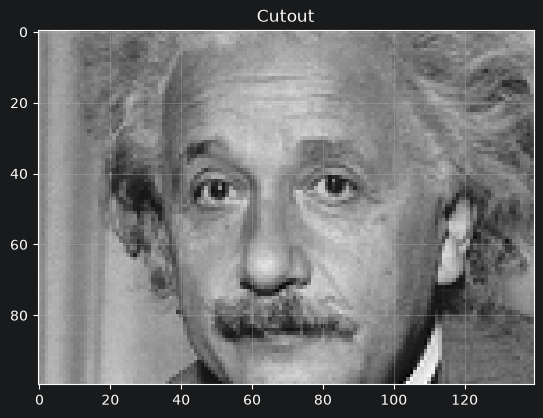

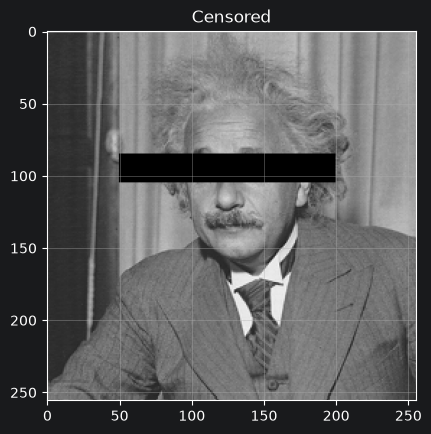

In [16]:
im = imageio.imread('../../data/test_images/einstein.jpg')
copim = np.copy(im[50:150, 60:200])
plt.imshow(copim, cmap='gray')
plt.title('Cutout')
plt.axis()
plt.grid()
plt.show()

im[85:105, 50:200] = 0
plt.imshow(im, cmap='gray')
plt.title('Censored')
plt.axis()
plt.grid()
plt.show()

imageio.imsave('einstein_censored.png', im)

## Exercise 3
### Basic image transforms (translate, flip, scale, rotation)

1. Read in image "einstein.jpg" again

2. Apply some image transforms to it (if you are unsure about how to use these functions, have a look at the API documentation: https://docs.scipy.org/doc/scipy/reference/ndimage.html and https://docs.scipy.org/doc/numpy/genindex.html :
    1. flip the image horizontally with function np.fliplr() and plot it
    2. translate the image with ndimage.shift() by 30 pixels horizontally and 60 pixels vertically and plot the result
    3. scale the image with ndimage.zoom(). 1. scale uniformly (same zoom factor for both axes) and plot the result. 2. next create a plot for non-uniformly zooming (different zoom factor for both axes).
    4. rotate the image with ndimage.rotate(). The function takes an additional parameter "reshape" which can be True or False. Try out both. What happens to the image? Plot both results. (Hint: in case you use 90°,180°,270° for the rotation you won't see any effect of the reshape option).
    

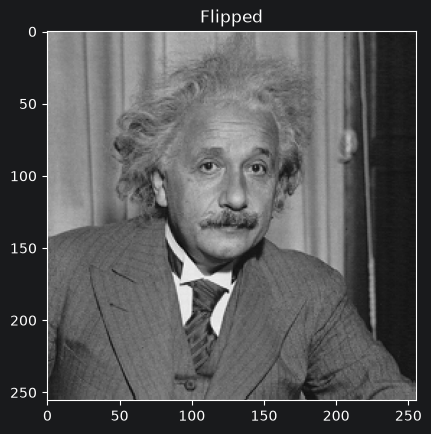

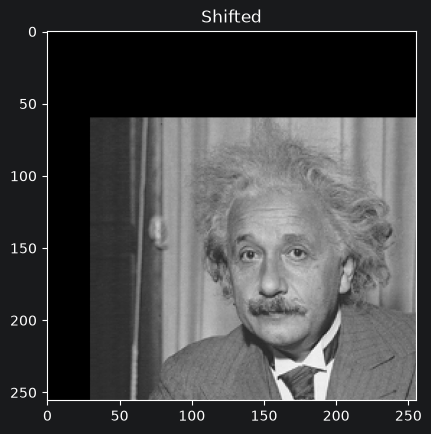

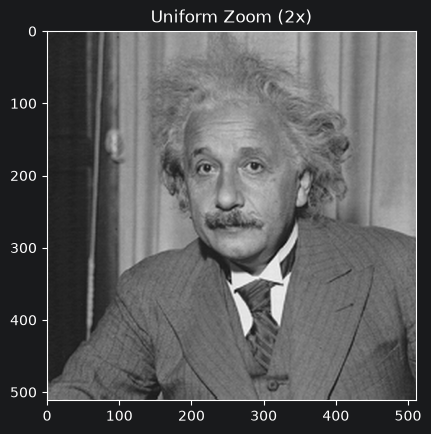

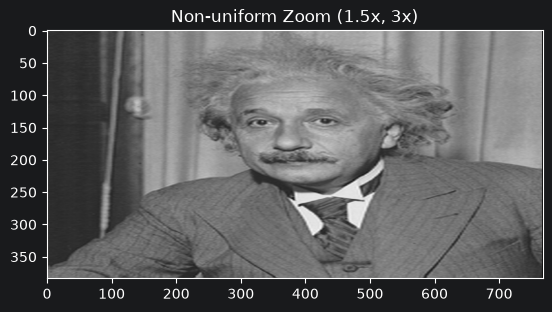

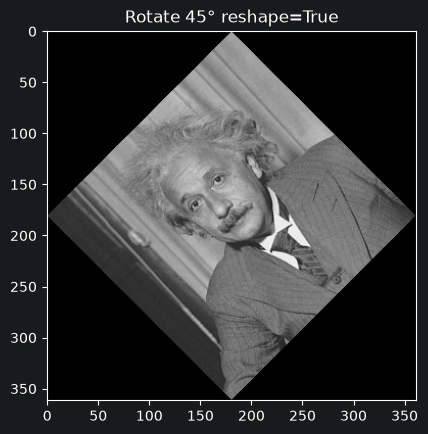

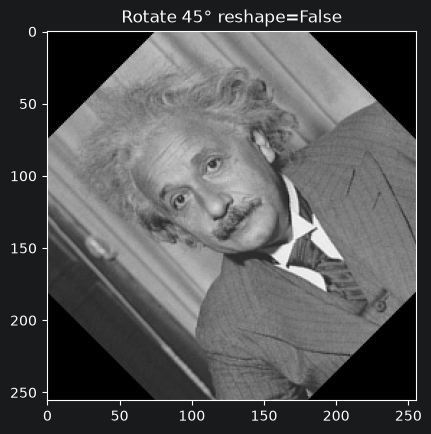

In [17]:
img_path = '../../data/test_images/'

im = imageio.imread(img_path + 'einstein.jpg')

# 1. flip horizontally
flipped = np.fliplr(im)
plt.imshow(flipped, cmap='gray')
plt.title('Flipped')
plt.show()

# 2. translate by 30px horizontal, 60px vertical
shifted = ndimage.shift(im, [60, 30])
plt.imshow(shifted, cmap='gray')
plt.title('Shifted')
plt.show()

# 3a. uniform zoom
zoomed_uniform = ndimage.zoom(im, 2.0)
plt.imshow(zoomed_uniform, cmap='gray')
plt.title('Uniform Zoom (2x)')
plt.show()

# 3b. non-uniform zoom
zoomed_non = ndimage.zoom(im, [1.5, 3.0])
plt.imshow(zoomed_non, cmap='gray')
plt.title('Non-uniform Zoom (1.5x, 3x)')
plt.show()

# 4. rotate with reshape=True and reshape=False
rotated_reshape = ndimage.rotate(im, 45, reshape=True)
plt.imshow(rotated_reshape, cmap='gray')
plt.title('Rotate 45° reshape=True')
plt.show()

rotated_no_reshape = ndimage.rotate(im, 45, reshape=False)
plt.imshow(rotated_no_reshape, cmap='gray')
plt.title('Rotate 45° reshape=False')
plt.show()

## Exercise 4 
### Simple pixel-wise image operations:  addition

Images are simple matrices. Thus, we can add two images of same size simply by adding their pixels. The same we can do with subtraction, multiplication and division. In all these cases, the operation is performed on each pixel individually. Note due to a concept called "broadcasting" in numpy, we do not need loops at all for such operations!

1. read in "einstein.jpg" in variable A and convert it to float (with .astype("float32")) 
2. copy A using np.copy() and assign it to variable B
3. use ndimage.rotate() to rotate image B 
4. add the two images together. Use np.add() for this and save the result in a variable "C". Note: this does not need any loops. The funciton just takes the two images as input and sums them up in a pixe-wise manner.
5. Show the result (set cmap='gray' again to get correct brightnesses)
6. Check the maximum and minimum value of the result (C) and its type (.dtype). What can we observe? Are the values still in range (0..255) as we would expect from a grayscale image?
7. Show the image with plt.imshow(C,cmap='gray',vmin=0,vmax=255). This sets limits for brightness (black = 0, white = 255). Now you can see that we oversaturated the image by adding the two images together
8. Add the images together by first dividing each image by a factor if two. You can do this by: im=im/2 (Note that again this does not need any loops and is automatically performed for all elements of "im" 

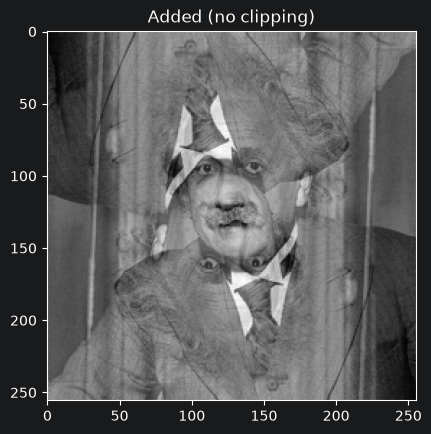

max: 400.0 min: 83.0 dtype: float32


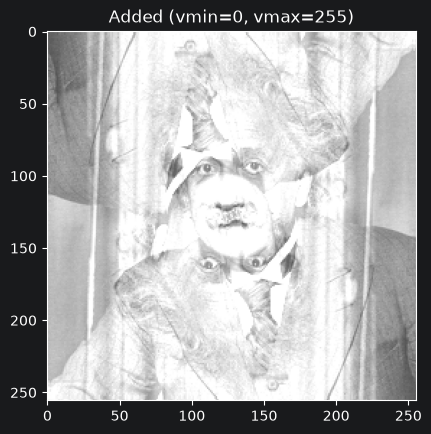

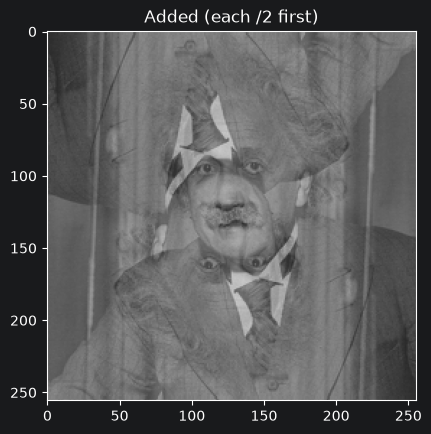

In [18]:
img_path = '../../data/test_images/'

A = imageio.imread(img_path + 'einstein.jpg').astype('float32')
B = np.copy(A)
B = ndimage.rotate(B, 180, reshape=False)

C = np.add(A, B)

plt.imshow(C, cmap='gray')
plt.title('Added (no clipping)')
plt.show()

print('max:', np.max(C), 'min:', np.min(C), 'dtype:', C.dtype)

plt.imshow(C, cmap='gray', vmin=0, vmax=255)
plt.title('Added (vmin=0, vmax=255)')
plt.show()

# proper way: divide each by 2 first
C2 = A/2 + B/2
plt.imshow(C2, cmap='gray', vmin=0, vmax=255)
plt.title('Added (each /2 first)')
plt.show()

## Exercise 5
### Simple pixel-wise image operations:  subtraction

1. Read in the two images son1.gif and son2.gif
2. Plot both images.
3. Output their shapes to make sure they are of same size
4. Before we subtract the two images we have to care about the values we might get after subtraction. Subtraction may produce negative values which cannot be represented by uint8 datatype. To avoid overflows in the datatype we have to convert the images to another datatype. You can do this with:  myIm = myIm.astype("float32");
5. Subtract the two images from each other with np.subtract() and store the result in C. Subtract B from A, i.e. A-B, not vice versa.
6. Check the value range of the resulting image C with np.min and np.max. Do we get negative values?
7. Plot the result of subtraction with: plt.imshow(C,cmap='gray',vmin=np.min(C),vmax=np.max(C)), plt.show(). This adapts the value range for plotting to the actual value range of C (i.e. the minimal pixel in C is considered black and the highest pixel is considered white.

As you can see in this example, subtraction can be used to remove the background from an image (in case the pure background is known and available as an image. 

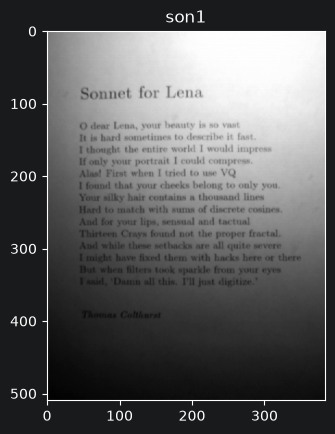

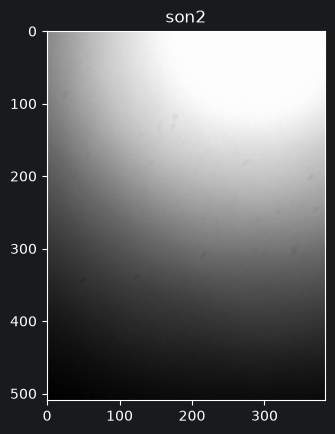

A shape: (510, 384) B shape: (510, 384)
min: -123.0 max: 4.0


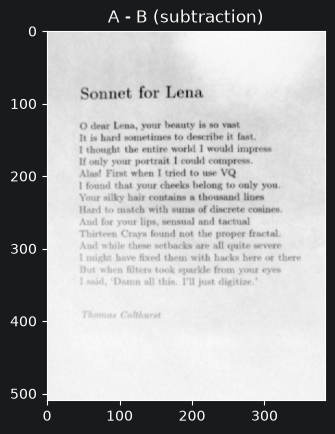

In [19]:
img_path = '../../data/test_images/'

A = imageio.imread(img_path + 'son1.gif')
B = imageio.imread(img_path + 'son2.gif')

plt.imshow(A, cmap='gray')
plt.title('son1')
plt.show()

plt.imshow(B, cmap='gray')
plt.title('son2')
plt.show()

print('A shape:', A.shape, 'B shape:', B.shape)

A = A.astype('float32')
B = B.astype('float32')

C = np.subtract(A, B)
print('min:', np.min(C), 'max:', np.max(C))

plt.imshow(C, cmap='gray', vmin=np.min(C), vmax=np.max(C))
plt.title('A - B (subtraction)')
plt.show()

## Exercise 6
### Simple pixel-wise image operations: division

1. load the two images scr1.gif and scr2.gif into variables A and B.
2. divide A by B with np.divide. Store the result in C
3. plot the two input images and the result. Use again plt.imshow(myIm,cmap='gray',vmin=np.min(myIm),vmax=np.max(myIm)), plt.show() to adapt the value range dynamically to the images (because after divsion the image is not anymore between 0..255
4. **Question:** How does the divided image look like? What does it show (look at the original images and how they differ)? At which locations is the result image black and where does it contain information? What can we detect from this image? Add your answer in a Markdown cell below.

Where both images are identical, A/B = 1 (appears as a uniform gray). Where they differ, the ratio deviates from 1, making those regions visible. The result highlights the differences between the two images - areas that changed appear bright or dark, while unchanged areas are constant. This can be used to detect changes or moving objects between two captures of the same scene.

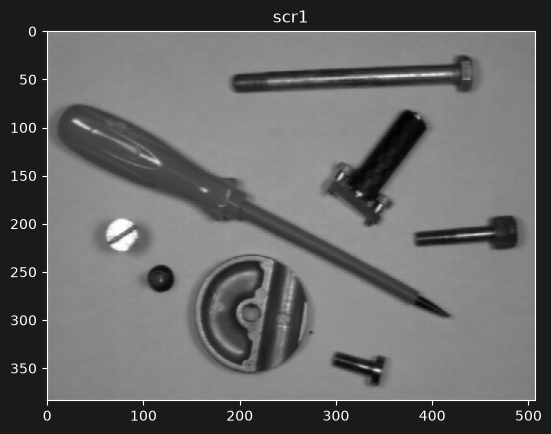

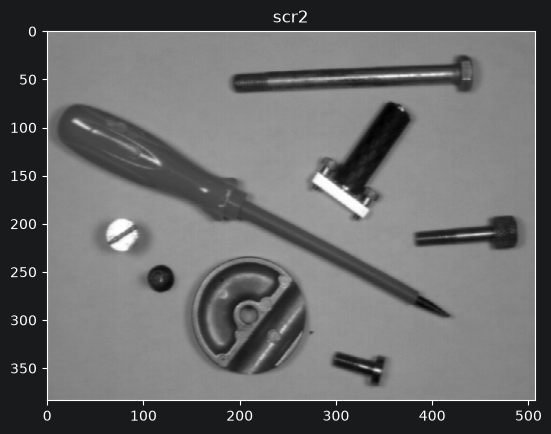

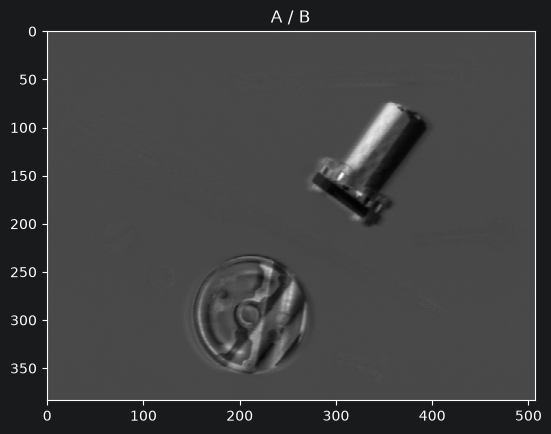

In [20]:
img_path = '../../data/test_images/'

A = imageio.imread(img_path + 'scr1.gif').astype('float32')
B = imageio.imread(img_path + 'scr2.GIF').astype('float32')

C = np.divide(A, B)

plt.imshow(A, cmap='gray', vmin=np.min(A), vmax=np.max(A))
plt.title('scr1')
plt.show()

plt.imshow(B, cmap='gray', vmin=np.min(B), vmax=np.max(B))
plt.title('scr2')
plt.show()

plt.imshow(C, cmap='gray', vmin=np.min(C), vmax=np.max(C))
plt.title('A / B')
plt.show()

## Exercise 7
### Image Thresholding

Let's do some simple image thresholding. Thresholding is the simplest way of segmenting images.

1. Load image son1sub.gif and show it.
2. define a threshold t, e.g. t=100
3. Set all pixels in the image which are lower than the threshold to 0 (Note: use logical indexing of numpy, see https://docs.scipy.org/doc/numpy/user/basics.indexing.html -> Section: "Boolean or “mask” index arrays"
4. Similarly, set all pixels in the same image which are greater or equal than the threshold to 1
5. Plot the resulting image. Note: You might not see too much, depending on the threshold
6. Vary the threshold manually to find a good value for t that separates the background and the text well.

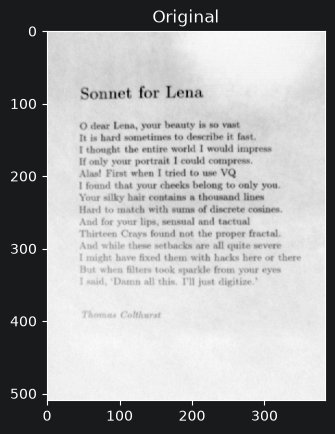

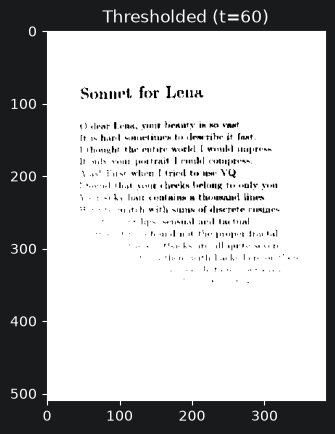

In [21]:
img_path = '../../data/test_images/'

im = imageio.imread(img_path + 'son1sub.gif').astype('float32')
plt.imshow(im, cmap='gray')
plt.title('Original')
plt.show()

t = 60
result = np.copy(im)
result[result < t] = 0
result[result >= t] = 1

plt.imshow(result, cmap='gray')
plt.title(f'Thresholded (t={t})')
plt.show()

## Exercise 8
### Remove motion from an image sequence


This task sounds more difficult than it actually is. In the package with the test files you find an image sequence (folder /sequence/Bootstrap. It contains images: im_0001.jpg to im_3055.jpg. The sequence shows people arriving, waiting in front of a desk and leaving again captured from a surveillance camera. Our task is to generate an image of this scene that does not contain any people at all. Note that there is no image in this sequence that shows the completely empty scene. We need to generate it from the images.

This is how it works:
1. import the following: from skimage.io import imread_collection
2. Use: col = imread_collection(col_dir + "/*.jpg") to read in all images. col_dir points to the folder where the jpg images of the sequence are located.
3. Convert the image collection "col" to a numpy array by simply generating a now numpy array with "col" as initial value: np.array(col)
4. Print the shape of the resulting numpy array. Interprete the individual dimensions. This is a four dimensional array. What is width, height, number of channels and what is the number of images? 
5. Now, plot the first, 100th and 200th images of the sequence, just to see if you understand the individual dimensions of the four-dimensional matrix correctly
6. Now comes the magic: compute an average image over the entire sequence. This image contains mostly the constant pixels (the background). Moving foreground objects will be filtered out by the mean. To compute the average use np.mean. Pass the four dimensional array and select the dimension over which the mean is computed. Hint: the dimensions are numbered 0,1,2,... and so on.
7. Take the result of the mean computation, convert it to uint8 (e.g. like this: myIm = myIm.astype("uint8") and plot it.
8. The result should be an empty image without any people in it


Shape: (3055, 60, 80, 3)


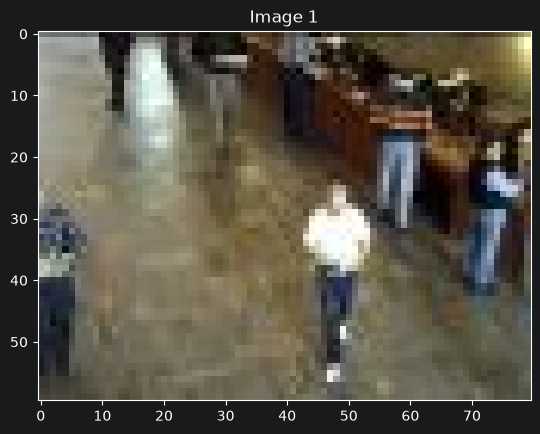

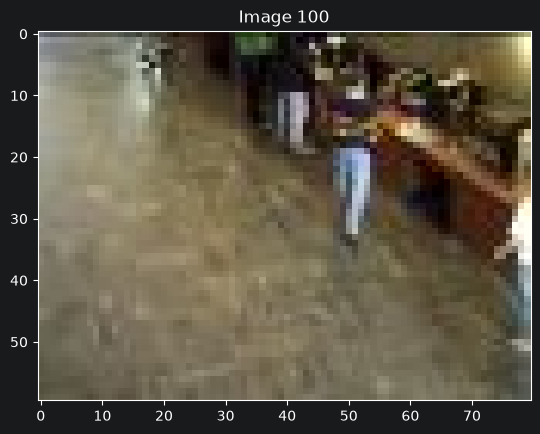

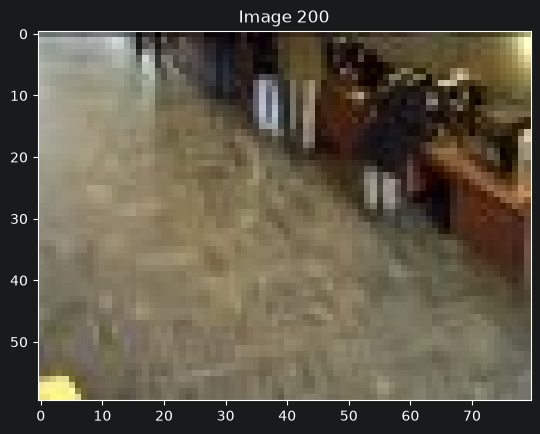

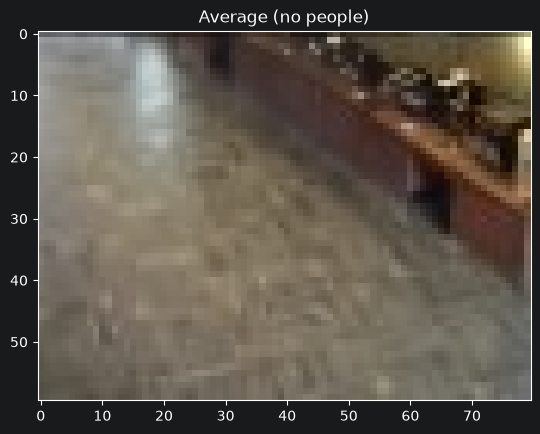

In [22]:
from skimage.io import imread_collection

col_dir = '../../data/test_images/sequence/Bootstrap'
col = imread_collection(col_dir + '/*.jpg')
images = np.array(col)
print('Shape:', images.shape)

plt.imshow(images[0])
plt.title('Image 1')
plt.show()

plt.imshow(images[99])
plt.title('Image 100')
plt.show()

plt.imshow(images[199])
plt.title('Image 200')
plt.show()

avg = np.mean(images, axis=0).astype('uint8')
plt.imshow(avg)
plt.title('Average (no people)')
plt.show()